# EDA: age and photos per person

Filtering applied on top of the team's cleaned dataset:
- Removed 95 photos with impossible ages (<0 or >100), from 42 people
- Removed 7 people left with only one distinct age after that
- Final: ~129.8k photos, ~8.1k people

In [1]:
import pandas as pd

df = pd.read_csv("../data/age.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.describe(include="all"))

(129943, 4)
['name', 'directory', 'age', 'gender']
                  name                                          directory  \
0  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1093319424_1959-10-23...   
1  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1126873856_1959-10-23...   
2  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1956049664_1959-10-23...   
3  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm3125254656_1959-10-23...   
4  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm3591961856_1959-10-23...   

   age  gender  
0   30       1  
1   30       1  
2   56       1  
3   30       1  
4   56       1  
                  name                                          directory  \
count           129943                                             129943   
unique            8127                                             129943   
top     Angelina Jolie  imdb_crop/48/nm0946148_rm1093319424_1959-10-23...   
freq               330                                                  1   

In [2]:
bad = df[(df["age"] < 0) | (df["age"] > 100)]
print("Bad rows:", len(bad), "| people affected:", bad["name"].nunique())
print(df["age"].lt(0).sum(), "negative |", df["age"].gt(100).sum(), "over 100")
print(bad.sort_values("age").head(10)[["name", "age", "directory"]])
print(bad.sort_values("age").tail(10)[["name", "age", "directory"]])

Bad rows: 95 | people affected: 42
88 negative | 7 over 100
                  name  age                                          directory
11011   Barbara Palvin  -30  imdb_crop/80/nm5435980_rm1770170112_1993-10-8_...
9680     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1214618112_1989-12-18...
9681     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1432721920_1989-12-18...
9682     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1449499136_1989-12-18...
9683     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1466276352_1989-12-18...
102904   Rachel Melvin  -20  imdb_crop/93/nm1560493_rm3160775168_1985-2-9_1...
102903   Rachel Melvin  -20  imdb_crop/93/nm1560493_rm3143997952_1985-2-9_1...
39858       Farah Fath  -19  imdb_crop/41/nm0268841_rm1365613056_1984-5-1_1...
39860       Farah Fath  -19  imdb_crop/41/nm0268841_rm1600494080_1984-5-1_1...
39859       Farah Fath  -19  imdb_crop/41/nm0268841_rm1583716864_1984-5-1_1...
                    name  age  \
71390     Kenan Thompson   -3   
86265

In [3]:
df_clean = df[(df["age"] >= 0) & (df["age"] <= 100)].copy()
print(len(df), "->", len(df_clean))

129943 -> 129848


In [4]:
per_person = df_clean.groupby("name").agg(
    photos=("age", "size"),
    distinct_ages=("age", "nunique"),
    age_span=("age", lambda s: s.max() - s.min()),
)
print(per_person.describe())

            photos  distinct_ages     age_span
count  8127.000000    8127.000000  8127.000000
mean     15.977359       4.882614    11.787868
std      24.481650       3.878445    10.388623
min       1.000000       1.000000     0.000000
25%       3.000000       2.000000     4.000000
50%       7.000000       3.000000     9.000000
75%      17.000000       6.000000    16.000000
max     330.000000      36.000000    63.000000


In [5]:
one_age = per_person[per_person["distinct_ages"] == 1]
print(len(one_age), "people with only one distinct age")
print(one_age.sort_values("photos", ascending=False).head(10))

7 people with only one distinct age
                 photos  distinct_ages  age_span
name                                            
David Fumero          2              1         0
Heather Lindell       2              1         0
Barbara Palvin        1              1         0
Farah Fath            1              1         0
Moms Mabley           1              1         0
Tamie Sheffield       1              1         0
Vanessa Bayer         1              1         0


In [6]:
keep = per_person[per_person["distinct_ages"] >= 2].index
df_clean = df_clean[df_clean["name"].isin(keep)].copy()
print(len(df_clean), "photos |", df_clean["name"].nunique(), "people")

129839 photos | 8120 people


In [10]:
per_person = df_clean.groupby("name").agg(
    photos=("age", "size"),
    distinct_ages=("age", "nunique"),
    age_span=("age", lambda s: s.max() - s.min()),
)
print(per_person.describe())

            photos  distinct_ages    age_span
count  8120.000000    8120.000000  8120.00000
mean     15.990025       4.885961    11.79803
std      24.488395       3.878440    10.38733
min       2.000000       2.000000     1.00000
25%       3.000000       2.000000     4.00000
50%       7.000000       3.000000     9.00000
75%      17.000000       6.000000    16.00000
max     330.000000      36.000000    63.00000


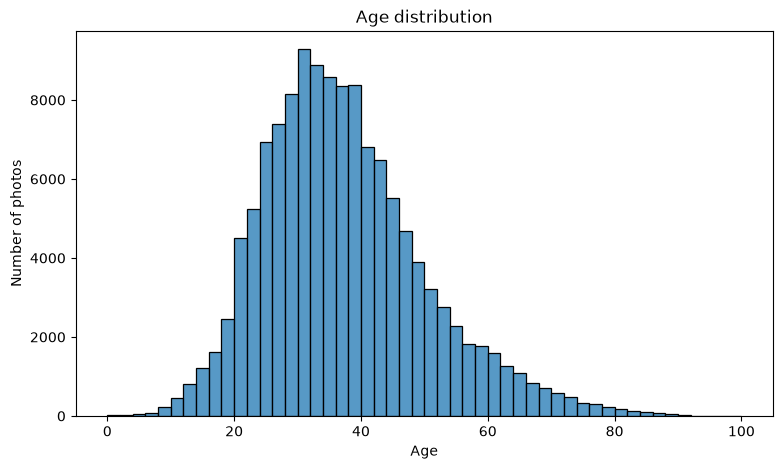

In [11]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(9, 5))
sns.histplot(df_clean["age"], bins=range(0, 101, 2))
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of photos")
plt.savefig("figures/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

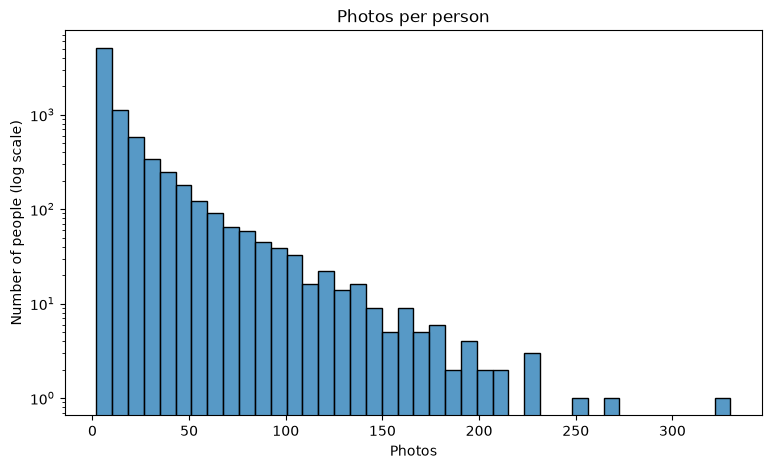

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(per_person["photos"], bins=40)
plt.yscale("log")
plt.title("Photos per person")
plt.xlabel("Photos")
plt.ylabel("Number of people (log scale)")
plt.savefig("figures/photos_per_person.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
print((per_person["photos"] <= 10).mean())
print((per_person["photos"] >= 100).sum(), "people with 100+ photos")
print((df_clean["age"] < 15).mean(), (df_clean["age"] > 70).mean())
print(df_clean["age"].median())

0.6262315270935961
154 people with 100+ photos
0.01725213533684024 0.01679772641502168
35.0


## Key observations
- Ages are right-skewed, peaking around 30-34 with a median of 35. Most photos are of people aged 20-50.
- Children (<15) and older adults (>70) are rare: each makes up only about 1.7% of photos. A model trained on this data will likely be weakest at producing very old faces, which matters for the aging task.
- Photos per person are heavily skewed: about 63% of people have 10 or fewer photos, while 154 people have 100+ (max 330). Training on all photos as-is would let a small group of celebrities dominate, so consider capping photos per person.
- Ethnicity is not labeled in this dataset, so it can't be analyzed. Gender is coded 0/1 and roughly balanced.